<a href="https://colab.research.google.com/github/ryukf333/salmonella-risk-prediction/blob/main/Models_and_Final_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Collect right Data set

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import pandas as pd
from pathlib import Path

# Project directory
PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

# Explicit input file
DATA_PATH = PROJECT_DIR / "data/processed/salmonella_model_v1.parquet"

# Verify the file exists
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Load the combined primary dataset
df = pd.read_parquet(DATA_PATH)

print("Dataset loaded successfully.")
print("Source:", DATA_PATH)
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Source: /content/drive/MyDrive/raw_poultry_ml/data/processed/salmonella_model_v1.parquet
Shape: (145183, 12)


,establishment_state,project_code,sample_source_name,product_type,collection_month,fiscal_year,establishment_id,collection_date,source_archive,source_row_number,salmonella_sp_analysis,target_salmonella
0,GA,HC_CH_CARC01,Animal-Chicken-Broiler / Young Chicken Carcass...,None,10,2022,3,2021-10-01,raw_poultry_sampling_data_fy2022.zip,1,Negative,0
1,GA,HC_CPT_LBW01,Product-Raw-Intact-Chicken,Breast,10,2022,32,2021-10-01,raw_poultry_sampling_data_fy2022.zip,2,Negative,0
2,GA,HC_CPT_LBW01,Product-Raw-Intact-Chicken,Leg,10,2022,39,2021-10-01,raw_poultry_sampling_data_fy2022.zip,3,Positive,1
3,GA,HC_CH_COM01,"Product-Raw-Ground, Comminuted or Otherwise No...",None,10,2022,41,2021-10-01,raw_poultry_sampling_data_fy2022.zip,4,Positive,1
4,SC,HC_CH_CARC01,Animal-Chicken-Broiler / Young Chicken Carcass...,None,10,2022,564,2021-10-01,raw_poultry_sampling_data_fy2022.zip,5,Negative,0


In [ ]:
import pandas as pd
from pathlib import Path

# Project directory
PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

# Explicit modeling dataset
DATA_PATH = PROJECT_DIR / "data/processed/salmonella_model_v1.parquet"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Modeling dataset not found: {DATA_PATH}\n"
        "Check the file's actual location before continuing."
    )

# Load Salmonella model v1
df = pd.read_parquet(DATA_PATH)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Verify the columns needed for population selection
required_cols = [
    "sample_source_name",
    "product_type",
    "target_salmonella",
    "fiscal_year"
]

missing_cols = [c for c in required_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Required columns not found: {missing_cols}")

# Inspect sample-source categories
print("\n1. Sample source categories")
display(
    df["sample_source_name"]
    .value_counts(dropna=False)
    .rename_axis("sample_source_name")
    .reset_index(name="count")
)

# Inspect product-type categories
print("\n2. Product type categories")
display(
    df["product_type"]
    .value_counts(dropna=False)
    .rename_axis("product_type")
    .reset_index(name="count")
)

# Inspect combinations of both columns
print("\n3. Sample source × product type")
display(
    pd.crosstab(
        df["sample_source_name"].fillna("[MISSING]"),
        df["product_type"].fillna("[MISSING]"),
        margins=True
    )
)

print("\n4. Labeled outcomes by fiscal year")
display(
    pd.crosstab(
        df["fiscal_year"],
        df["target_salmonella"],
        margins=True
    )
)

Dataset: /content/drive/MyDrive/raw_poultry_ml/data/processed/salmonella_model_v1.parquet
Shape: (145183, 12)

Columns:
['establishment_state', 'project_code', 'sample_source_name', 'product_type', 'collection_month', 'fiscal_year', 'establishment_id', 'collection_date', 'source_archive', 'source_row_number', 'salmonella_sp_analysis', 'target_salmonella']

1. Sample source categories


,sample_source_name,count
0,Product-Raw-Intact-Chicken,67133
1,Animal-Chicken-Broiler / Young Chicken Carcass...,50810
2,"Product-Raw-Ground, Comminuted or Otherwise No...",15763
3,"Product-Raw-Ground, Comminuted or Otherwise No...",6353
4,Animal-Turkey-Turkey Carcass Sponge,5121
5,Animal-Chicken-Young Chicken,3



2. Product type categories


,product_type,count
0,None,70700
1,Breast,34811
2,Leg,25443
3,Wing,14051
4,Quarter-Carcass,136
5,Half-Carcass,38
6,Whole Liver (only whole livers should be colle...,2
7,Gizzard,1
8,Neck,1



3. Sample source × product type


product_type,Breast,Gizzard,Half-Carcass,Leg,Neck,Quarter-Carcass,"Whole Liver (only whole livers should be collected, not pieces of livers)",Wing,[MISSING],All
sample_source_name,,,,,,,,,,
Animal-Chicken-Broiler / Young Chicken Carcass Rinse,0,0,0,0,0,0,0,0,50810,50810
Animal-Chicken-Young Chicken,1,0,0,0,0,0,0,0,2,3
Animal-Turkey-Turkey Carcass Sponge,0,0,0,0,0,0,0,0,5121,5121
"Product-Raw-Ground, Comminuted or Otherwise Nonintact-Chicken",3768,0,0,2456,0,3,0,1141,8395,15763
"Product-Raw-Ground, Comminuted or Otherwise Nonintact-Turkey",0,0,0,0,0,0,0,0,6353,6353
Product-Raw-Intact-Chicken,31042,1,38,22987,1,133,2,12910,19,67133
All,34811,1,38,25443,1,136,2,14051,70700,145183



4. Labeled outcomes by fiscal year


target_salmonella,0,1,All
fiscal_year,,,
2022,29708,4902,34610
2023,28381,3639,32020
2024,26429,2476,28905
2025,25756,2798,28554
2026,19053,2041,21094
All,129327,15856,145183


# Filtered necessary chicken parts

In [ ]:
import pandas as pd
from pathlib import Path

# Explicit source: prepared Salmonella modeling dataset
PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")
INPUT_PATH = PROJECT_DIR / "data/processed/salmonella_model_v1.parquet"

df = pd.read_parquet(INPUT_PATH)

# Define the study population
TARGET_SOURCE = "Product-Raw-Intact-Chicken"
TARGET_PARTS = ["Breast", "Leg", "Wing"]

df_parts = df.loc[
    df["sample_source_name"].eq(TARGET_SOURCE)
    & df["product_type"].isin(TARGET_PARTS)
].copy()

# Verify the filtered dataset
print("Original dataset shape:", df.shape)
print("Filtered dataset shape:", df_parts.shape)

print("\nCounts by product type:")
display(df_parts["product_type"].value_counts())

print("\nSalmonella outcomes by product type:")
display(pd.crosstab(
    df_parts["product_type"],
    df_parts["target_salmonella"],
    margins=True
))

print("\nSalmonella outcomes by fiscal year:")
display(pd.crosstab(
    df_parts["fiscal_year"],
    df_parts["target_salmonella"],
    margins=True
))

# Save as a new intermediate dataset
OUTPUT_PATH = PROJECT_DIR / "data/processed/salmonella_chicken_parts_v1.parquet"
df_parts.to_parquet(OUTPUT_PATH, index=False)

print("\nFiltered dataset saved to:", OUTPUT_PATH)

Original dataset shape: (145183, 12)
Filtered dataset shape: (66939, 12)

Counts by product type:


,count
product_type,
Breast,31042
Leg,22987
Wing,12910



Salmonella outcomes by product type:


target_salmonella,0,1,All
product_type,,,
Breast,28323,2719,31042
Leg,21214,1773,22987
Wing,11684,1226,12910
All,61221,5718,66939



Salmonella outcomes by fiscal year:


target_salmonella,0,1,All
fiscal_year,,,
2022,12811,1089,13900
2023,12861,1285,14146
2024,13107,1220,14327
2025,12934,1250,14184
2026,9508,874,10382
All,61221,5718,66939



Filtered dataset saved to: /content/drive/MyDrive/raw_poultry_ml/data/processed/salmonella_chicken_parts_v1.parquet


In [ ]:


PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

DATA_PATH = (
    PROJECT_DIR
    / "data/processed/salmonella_chicken_parts_v1.parquet"
)

df_parts = pd.read_parquet(DATA_PATH)

print("Dataset shape:", df_parts.shape)

# Confirm inclusion criteria
print("\nSample sources:")
print(df_parts["sample_source_name"].value_counts(dropna=False))

print("\nProduct types:")
print(df_parts["product_type"].value_counts(dropna=False))

# Verify target labels
print("\nTarget values:")
print(df_parts["target_salmonella"].value_counts(dropna=False))

# Check missing predictor values
candidate_features = [
    "establishment_state",
    "project_code",
    "sample_source_name",
    "product_type",
    "collection_month"
]

print("\nMissingness in candidate predictors:")
display(pd.DataFrame({
    "missing_count": df_parts[candidate_features].isna().sum(),
    "missing_percent": (
        df_parts[candidate_features].isna().mean() * 100
    ).round(2)
}))

# Check establishment overlap across years
print("\nUnique establishments by fiscal year:")
display(
    df_parts.groupby("fiscal_year")["establishment_id"]
    .nunique()
    .rename("unique_establishments")
    .to_frame()
)

# Check whether target labels match the original test results
print("\nOriginal label vs model target:")
display(pd.crosstab(
    df_parts["salmonella_sp_analysis"],
    df_parts["target_salmonella"],
    dropna=False
))

Dataset shape: (66939, 12)

Sample sources:
sample_source_name
Product-Raw-Intact-Chicken    66939
Name: count, dtype: int64

Product types:
product_type
Breast    31042
Leg       22987
Wing      12910
Name: count, dtype: int64

Target values:
target_salmonella
0    61221
1     5718
Name: count, dtype: int64

Missingness in candidate predictors:


,missing_count,missing_percent
establishment_state,0,0.0
project_code,0,0.0
sample_source_name,0,0.0
product_type,0,0.0
collection_month,0,0.0



Unique establishments by fiscal year:


,unique_establishments
fiscal_year,
2022,473
2023,477
2024,484
2025,620
2026,589



Original label vs model target:


target_salmonella,0,1
salmonella_sp_analysis,,
Negative,61221,0
Positive,0,5718


# Baseline

In [ ]:

# CELL 1: Load and verify the frozen modeling dataset
import pandas as pd
from pathlib import Path
PROJECT_DIR = Path(
    "/content/drive/MyDrive/raw_poultry_ml"
)

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "salmonella_chicken_parts_v1.parquet"
)

REPORT_DIR = PROJECT_DIR / "reports" / "results"
MODELS_DIR = PROJECT_DIR / "models"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load the existing dataset
df_model = pd.read_parquet(DATA_PATH)

# Define features and target
FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month"
]

TARGET = "target_salmonella"
YEAR_COL = "fiscal_year"

# Verify required columns
required_columns = FEATURES + [TARGET, YEAR_COL]

missing_columns = [
    c for c in required_columns
    if c not in df_model.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Verify target and year values
if df_model[TARGET].isna().any():
    raise ValueError("Missing target values detected.")

if not df_model[TARGET].isin([0, 1]).all():
    raise ValueError("Target must contain only 0 and 1.")

if not set(df_model[YEAR_COL].unique()).issubset(
    {2022, 2023, 2024, 2025, 2026}
):
    raise ValueError("Unexpected fiscal year detected.")

print("DATASET VERIFIED")
print("File:", DATA_PATH)
print("Shape:", df_model.shape)
print("Features:", FEATURES)

print("\nTarget distribution:")
display(
    df_model[TARGET]
    .value_counts()
    .rename(index={0: "Negative", 1: "Positive"})
    .to_frame("count")
)

print("\nRecords by fiscal year:")
display(
    df_model.groupby(YEAR_COL).agg(
        records=(TARGET, "size"),
        positive_count=(TARGET, "sum"),
        positive_rate=(TARGET, "mean")
    ).round(4)
)

print("\nThe original modeling dataset has not been modified.")


DATASET VERIFIED
File: /content/drive/MyDrive/raw_poultry_ml/data/processed/salmonella_chicken_parts_v1.parquet
Shape: (66939, 12)
Features: ['establishment_state', 'project_code', 'product_type', 'collection_month']

Target distribution:


,count
target_salmonella,
Negative,61221
Positive,5718



Records by fiscal year:


,records,positive_count,positive_rate
fiscal_year,,,
2022,13900,1089,0.0783
2023,14146,1285,0.0908
2024,14327,1220,0.0852
2025,14184,1250,0.0881
2026,10382,874,0.0842



The original modeling dataset has not been modified.


In [ ]:

# CELL 2: Temporal split and shared ML utilities

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

# --------------------------------------------------
# 1. Define the predictors and target
# --------------------------------------------------
FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month",
]

TARGET = "target_salmonella"
YEAR_COL = "fiscal_year"

# Confirm required columns
required_columns = FEATURES + [TARGET, YEAR_COL]

missing_columns = [
    col for col in required_columns
    if col not in df_model.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Do not include IDs, original labels, or provenance fields
# in the predictor matrix.

# --------------------------------------------------
# 2. Create chronological splits
# --------------------------------------------------
train_df = df_model[
    df_model[YEAR_COL].isin([2022, 2023, 2024])
].copy()

val_df = df_model[
    df_model[YEAR_COL] == 2025
].copy()

test_df = df_model[
    df_model[YEAR_COL] == 2026
].copy()

if train_df.empty or val_df.empty or test_df.empty:
    raise ValueError(
        "A training, validation, or test split is empty."
    )

# Confirm all splits have both target classes
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    if data[TARGET].nunique() != 2:
        raise ValueError(
            f"{name} split does not contain both target classes."
        )

# --------------------------------------------------
# 3. Display split statistics
# --------------------------------------------------
split_summary = pd.DataFrame([
    {
        "split": "Training",
        "years": "2022–2024",
        "records": len(train_df),
        "positive": int(train_df[TARGET].sum()),
        "negative": int((train_df[TARGET] == 0).sum()),
        "positive_rate_pct": round(
            train_df[TARGET].mean() * 100, 2
        ),
    },
    {
        "split": "Validation",
        "years": "2025",
        "records": len(val_df),
        "positive": int(val_df[TARGET].sum()),
        "negative": int((val_df[TARGET] == 0).sum()),
        "positive_rate_pct": round(
            val_df[TARGET].mean() * 100, 2
        ),
    },
    {
        "split": "Final test",
        "years": "2026",
        "records": len(test_df),
        "positive": int(test_df[TARGET].sum()),
        "negative": int((test_df[TARGET] == 0).sum()),
        "positive_rate_pct": round(
            test_df[TARGET].mean() * 100, 2
        ),
    },
])

display(split_summary)

# --------------------------------------------------
# 4. Shared preprocessing function
# --------------------------------------------------
def prepare_X(data):
    """Convert selected predictors to categorical strings."""

    X = data[FEATURES].copy()

    for col in FEATURES:
        X[col] = (
            X[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    return X


def make_preprocessor():
    """Create one-hot encoding for all four predictors."""

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                Pipeline([
                    (
                        "imputer",
                        SimpleImputer(
                            strategy="most_frequent"
                        ),
                    ),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore"
                        ),
                    ),
                ]),
                FEATURES,
            )
        ],
        remainder="drop",
    )


def make_pipeline(estimator):
    """Build a consistent preprocessing/model pipeline."""

    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", estimator),
    ])


# --------------------------------------------------
# 5. Shared evaluation function
# --------------------------------------------------
def evaluate_model(model, X, y, threshold=0.5):
    """Calculate metrics from predicted positive probabilities."""

    probabilities = model.predict_proba(X)[:, 1]
    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "average_precision": average_precision_score(
            y, probabilities
        ),
        "roc_auc": roc_auc_score(
            y, probabilities
        ),
        "precision": precision_score(
            y, predictions, zero_division=0
        ),
        "recall": recall_score(
            y, predictions, zero_division=0
        ),
        "f1": f1_score(
            y, predictions, zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y, predictions
        ),
    }


# --------------------------------------------------
# 6. Prepare feature matrices
# --------------------------------------------------
X_train = prepare_X(train_df)
y_train = train_df[TARGET].astype(int)

X_val = prepare_X(val_df)
y_val = val_df[TARGET].astype(int)

X_test = prepare_X(test_df)
y_test = test_df[TARGET].astype(int)

print("\nTemporal splits prepared successfully.")
print("Predictors:", FEATURES)
print("Target:", TARGET)
print("FY2026 remains reserved for final testing.")


,split,years,records,positive,negative,positive_rate_pct
0,Training,2022–2024,42373,3594,38779,8.48
1,Validation,2025,14184,1250,12934,8.81
2,Final test,2026,10382,874,9508,8.42



Temporal splits prepared successfully.
Predictors: ['establishment_state', 'project_code', 'product_type', 'collection_month']
Target: target_salmonella
FY2026 remains reserved for final testing.


In [ ]:

# CELL 3: DummyClassifier baseline

from sklearn.dummy import DummyClassifier
import pandas as pd

# 1. Create the baseline model using the shared pipeline
dummy_model = make_pipeline(
    DummyClassifier(strategy="prior")
)

# 2. Train on FY2022–FY2024 only
dummy_model.fit(X_train, y_train)

# 3. Evaluate on FY2025 validation data
dummy_metrics = evaluate_model(
    dummy_model,
    X_val,
    y_val,
    threshold=0.5
)

dummy_metrics["model"] = "DummyClassifier"
dummy_metrics["threshold"] = 0.5
dummy_metrics["training_positive_rate"] = y_train.mean()
dummy_metrics["validation_positive_rate"] = y_val.mean()

# 4. Display baseline results
dummy_results_df = pd.DataFrame([dummy_metrics])

display(
    dummy_results_df[
        [
            "model",
            "training_positive_rate",
            "validation_positive_rate",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
        ]
    ].round(4)
)

# 5. Save the baseline results
baseline_path = (
    PROJECT_DIR
    / "reports"
    / "results"
    / "dummy_validation_baseline.csv"
)

dummy_results_df.to_csv(
    baseline_path,
    index=False
)

print("\nBaseline results saved to:", baseline_path)

print(
    "\nFY2025 positive cases detected at threshold 0.5:",
    int(
        (
            dummy_model.predict_proba(X_val)[:, 1] >= 0.5
        ).sum()
    )
)


,model,training_positive_rate,validation_positive_rate,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,DummyClassifier,0.0848,0.0881,0.0881,0.5,0.0,0.0,0.0,0.5



Baseline results saved to: /content/drive/MyDrive/raw_poultry_ml/reports/results/dummy_validation_baseline.csv

FY2025 positive cases detected at threshold 0.5: 0


In [ ]:

# CELL 4: Train and evaluate Logistic Regression

import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression

# --------------------------------------------------
# 1. Define the model
# --------------------------------------------------
logistic_model = make_pipeline(
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

# --------------------------------------------------
# 2. Train on FY2022–FY2024
# --------------------------------------------------
logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

# --------------------------------------------------
# 3. Predict on FY2025 validation data
# --------------------------------------------------
lr_prob = logistic_model.predict_proba(X_val)[:, 1]

# Use 0.5 for initial comparison with DummyClassifier
# We can assess other thresholds after comparing models.
lr_pred = (lr_prob >= 0.5).astype(int)

# --------------------------------------------------
# 4. Calculate evaluation metrics
# --------------------------------------------------
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix
)

lr_metrics = {
    "model": "Logistic Regression",
    "threshold": 0.5,
    "average_precision": average_precision_score(
        y_val, lr_prob
    ),
    "roc_auc": roc_auc_score(
        y_val, lr_prob
    ),
    "precision": precision_score(
        y_val, lr_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, lr_pred, zero_division=0
    ),
    "f1": f1_score(
        y_val, lr_pred, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_val, lr_pred
    )
}

lr_results_df = pd.DataFrame([lr_metrics])

display(lr_results_df.round(4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, lr_pred, labels=[0, 1]))

# --------------------------------------------------
# 5. Save results and the fitted validation model
# --------------------------------------------------
lr_results_path = (
    REPORTS_DIR / "logistic_regression_validation.csv"
)

lr_model_path = (
    MODELS_DIR / "logistic_regression_validation.joblib"
)

lr_results_df.to_csv(lr_results_path, index=False)
joblib.dump(logistic_model, lr_model_path)

print("\nResults saved:", lr_results_path)
print("Validation model saved:", lr_model_path)

print("\nPredicted-positive samples:", int(lr_pred.sum()))
print("Actual-positive samples:", int(y_val.sum()))


Logistic Regression training completed.


,model,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,Logistic Regression,0.5,0.124,0.5756,0.1094,0.476,0.1779,0.5507



Confusion matrix:
[[8089 4845]
 [ 655  595]]

Results saved: /content/drive/MyDrive/raw_poultry_ml/reports/results/logistic_regression_validation.csv
Validation model saved: /content/drive/MyDrive/raw_poultry_ml/models/logistic_regression_validation.joblib

Predicted-positive samples: 5440
Actual-positive samples: 1250


In [ ]:

# CELL 5: Train and evaluate Random Forest

import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

# 1. Define the model
rf_model = make_pipeline(
    RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )
)

# 2. Fit on FY2022-FY2024
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

# 3. Predict on FY2025 validation data
rf_prob = rf_model.predict_proba(X_val)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

# 4. Calculate metrics using the same threshold
rf_metrics = {
    "model": "Random Forest",
    "threshold": 0.5,
    "average_precision": average_precision_score(
        y_val, rf_prob
    ),
    "roc_auc": roc_auc_score(
        y_val, rf_prob
    ),
    "precision": precision_score(
        y_val, rf_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, rf_pred, zero_division=0
    ),
    "f1": f1_score(
        y_val, rf_pred, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_val, rf_pred
    ),
}

rf_results_df = pd.DataFrame([rf_metrics])
display(rf_results_df.round(4))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, rf_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_val,
    rf_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0,
))

# 5. Save the validation results and fitted model
rf_results_path = (
    REPORTS_DIR / "random_forest_validation.csv"
)

rf_model_path = (
    MODELS_DIR / "random_forest_validation.joblib"
)

rf_results_df.to_csv(rf_results_path, index=False)
joblib.dump(rf_model, rf_model_path)

print("\nResults saved:", rf_results_path)
print("Model saved:", rf_model_path)
print("Predicted-positive samples:", int(rf_pred.sum()))


Random Forest training completed.


,model,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,Random Forest,0.5,0.1144,0.5601,0.1098,0.4536,0.1769,0.5492



Confusion matrix:
[[8339 4595]
 [ 683  567]]

Classification report:
              precision    recall  f1-score   support

    Negative       0.92      0.64      0.76     12934
    Positive       0.11      0.45      0.18      1250

    accuracy                           0.63     14184
   macro avg       0.52      0.55      0.47     14184
weighted avg       0.85      0.63      0.71     14184


Results saved: /content/drive/MyDrive/raw_poultry_ml/reports/results/random_forest_validation.csv
Model saved: /content/drive/MyDrive/raw_poultry_ml/models/random_forest_validation.joblib
Predicted-positive samples: 5162


In [ ]:

# CELL 6: Train and evaluate XGBoost

import pandas as pd
import joblib

from xgboost import XGBClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

# --------------------------------------------------
# 1. Define XGBoost
# --------------------------------------------------
# Adjust the training loss for the imbalanced target.
# All parameters are fixed for this initial baseline.

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

if positive_count == 0:
    raise ValueError("No positive cases in the training data.")

positive_weight = negative_count / positive_count

xgb_estimator = XGBClassifier(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    scale_pos_weight=positive_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)

xgb_model = make_pipeline(xgb_estimator)

# --------------------------------------------------
# 2. Train on FY2022-FY2024
# --------------------------------------------------
xgb_model.fit(X_train, y_train)

print("XGBoost training completed.")
print("Scale_pos_weight:", round(positive_weight, 3))

# --------------------------------------------------
# 3. Predict on FY2025 validation data
# --------------------------------------------------
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

# Use the same initial threshold as the other models
xgb_pred = (xgb_prob >= 0.5).astype(int)

# --------------------------------------------------
# 4. Calculate validation metrics
# --------------------------------------------------
xgb_metrics = {
    "model": "XGBoost",
    "threshold": 0.5,
    "average_precision": average_precision_score(
        y_val, xgb_prob
    ),
    "roc_auc": roc_auc_score(
        y_val, xgb_prob
    ),
    "precision": precision_score(
        y_val, xgb_pred, zero_division=0
    ),
    "recall": recall_score(
        y_val, xgb_pred, zero_division=0
    ),
    "f1": f1_score(
        y_val, xgb_pred, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_val, xgb_pred
    ),
}

xgb_results_df = pd.DataFrame([xgb_metrics])

print("\nXGBOOST VALIDATION RESULTS")
display(xgb_results_df.round(4))

# --------------------------------------------------
# 5. Show classification results
# --------------------------------------------------
print("\nConfusion matrix:")
print(confusion_matrix(y_val, xgb_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_val,
    xgb_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0,
    digits=4,
))

print("\nPredicted-positive samples:", int(xgb_pred.sum()))
print("Actual-positive samples:", int(y_val.sum()))

# --------------------------------------------------
# 6. Save the results and validation model
# --------------------------------------------------
xgb_results_path = (
    REPORTS_DIR / "xgboost_validation.csv"
)

xgb_model_path = (
    MODELS_DIR / "xgboost_validation.joblib"
)

xgb_results_df.to_csv(xgb_results_path, index=False)
joblib.dump(xgb_model, xgb_model_path)

print("\nResults saved:", xgb_results_path)
print("Validation model saved:", xgb_model_path)


XGBoost training completed.
Scale_pos_weight: 10.79

XGBOOST VALIDATION RESULTS


,model,threshold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,XGBoost,0.5,0.1189,0.5681,0.1083,0.4816,0.1769,0.5493



Confusion matrix:
[[7979 4955]
 [ 648  602]]

Classification report:
              precision    recall  f1-score   support

    Negative     0.9249    0.6169    0.7401     12934
    Positive     0.1083    0.4816    0.1769      1250

    accuracy                         0.6050     14184
   macro avg     0.5166    0.5493    0.4585     14184
weighted avg     0.8529    0.6050    0.6905     14184


Predicted-positive samples: 5557
Actual-positive samples: 1250

Results saved: /content/drive/MyDrive/raw_poultry_ml/reports/results/xgboost_validation.csv
Validation model saved: /content/drive/MyDrive/raw_poultry_ml/models/xgboost_validation.joblib


In [ ]:

# CELL 7: Consolidate baseline validation results

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/raw_poultry_ml"
)

RESULTS_DIR = PROJECT_DIR / "reports" / "results"

result_files = {
    "DummyClassifier":
        RESULTS_DIR / "dummy_validation_baseline.csv",

    "Logistic Regression":
        RESULTS_DIR / "logistic_regression_validation.csv",

    "Random Forest":
        RESULTS_DIR / "random_forest_validation.csv",

    "XGBoost":
        RESULTS_DIR / "xgboost_validation.csv",
}

results = []

for model_name, file_path in result_files.items():

    if not file_path.exists():
        raise FileNotFoundError(
            f"Result file not found: {file_path}"
        )

    result_df = pd.read_csv(file_path)

    if len(result_df) != 1:
        raise ValueError(
            f"Expected one result row in {file_path}"
        )

    row = result_df.iloc[0].to_dict()
    row["model"] = model_name
    results.append(row)

comparison_df = pd.DataFrame(results)

# Sort trained models first by average precision.
# Keep the DummyClassifier in the report for comparison.
dummy_row = comparison_df[
    comparison_df["model"] == "DummyClassifier"
]

trained_rows = comparison_df[
    comparison_df["model"] != "DummyClassifier"
].sort_values("average_precision", ascending=False)

comparison_df = pd.concat(
    [dummy_row, trained_rows],
    ignore_index=True
)

display(
    comparison_df[
        [
            "model",
            "average_precision",
            "roc_auc",
            "precision",
            "recall",
            "f1",
            "balanced_accuracy",
        ]
    ].round(4)
)

output_path = RESULTS_DIR / "all_baseline_comparison.csv"

comparison_df.to_csv(output_path, index=False)

print("\nComparison saved to:", output_path)


,model,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,DummyClassifier,0.0881,0.5000,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.1240,0.5756,0.1094,0.4760,0.1779,0.5507
2,XGBoost,0.1189,0.5681,0.1083,0.4816,0.1769,0.5493
3,Random Forest,0.1144,0.5601,0.1098,0.4536,0.1769,0.5492



Comparison saved to: /content/drive/MyDrive/raw_poultry_ml/reports/results/all_baseline_comparison.csv


# without project_code

In [ ]:
# CELL 1: Set up the experiment without project_code



from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/raw_poultry_ml"
)

DATA_PATH = (
    PROJECT_DIR
    / "data/processed/salmonella_chicken_parts_v1.parquet"
)

REPORT_DIR = (
    PROJECT_DIR
    / "reports/results/without_project_code"
)

MODEL_DIR = (
    PROJECT_DIR
    / "models/experiments/without_project_code"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load the original modeling dataset
df_model = pd.read_parquet(DATA_PATH)

# Exclude project_code deliberately
FEATURES_NO_PROJECT = [
    "establishment_state",
    "product_type",
    "collection_month",
]

TARGET = "target_salmonella"
YEAR_COL = "fiscal_year"

required = FEATURES_NO_PROJECT + [TARGET, YEAR_COL]
missing = [c for c in required if c not in df_model.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

if not df_model[TARGET].isin([0, 1]).all():
    raise ValueError("Target must contain only 0 and 1.")

# Use exactly the same temporal split as the previous models
train_df = df_model[
    df_model[YEAR_COL].isin([2022, 2023, 2024])
].copy()

val_df = df_model[
    df_model[YEAR_COL] == 2025
].copy()

test_df = df_model[
    df_model[YEAR_COL] == 2026
].copy()

def prepare_X(data, features=FEATURES_NO_PROJECT):
    """Prepare predictors consistently for all three models."""
    X = data[features].copy()

    for col in features:
        X[col] = (
            X[col]
            .astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    return X

X_train = prepare_X(train_df)
y_train = train_df[TARGET].astype(int)

X_val = prepare_X(val_df)
y_val = val_df[TARGET].astype(int)

X_test = prepare_X(test_df)
y_test = test_df[TARGET].astype(int)

def make_preprocessor():
    return ColumnTransformer([
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            FEATURES_NO_PROJECT,
        )
    ])

def make_pipeline(estimator):
    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("model", estimator),
    ])

def evaluate_model(model, X, y, threshold=0.5):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return {
        "average_precision": average_precision_score(y, probabilities),
        "roc_auc": roc_auc_score(y, probabilities),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
    }

# Separate experiment results; nothing from the previous
# experiment's result dictionary is reused.
results_no_project = []
models_no_project = {}

print("Experiment: WITHOUT project_code")
print("Dataset:", DATA_PATH)
print("Dataset rows:", len(df_model))
print("Features:", FEATURES_NO_PROJECT)
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Final test rows:", len(test_df))

print("\nFY2026 is reserved for final testing.")

Experiment: WITHOUT project_code
Dataset: /content/drive/MyDrive/raw_poultry_ml/data/processed/salmonella_chicken_parts_v1.parquet
Dataset rows: 66939
Features: ['establishment_state', 'product_type', 'collection_month']
Training rows: 42373
Validation rows: 14184
Final test rows: 10382

FY2026 is reserved for final testing.


#

In [ ]:
# CELL 2: Logistic Regression without project_code

from sklearn.linear_model import LogisticRegression

lr_no_project = make_pipeline(
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    )
)

lr_no_project.fit(X_train, y_train)

lr_metrics_no_project = evaluate_model(
    lr_no_project, X_val, y_val, threshold=0.5
)

lr_metrics_no_project["model"] = "Logistic Regression"
lr_metrics_no_project["features"] = "Without project_code"
lr_metrics_no_project["threshold"] = 0.5

results_no_project.append(lr_metrics_no_project)
models_no_project["Logistic Regression"] = lr_no_project

print("Logistic Regression — validation results")
display(pd.DataFrame([lr_metrics_no_project]).round(4))

lr_prob_no_project = lr_no_project.predict_proba(X_val)[:, 1]
lr_pred_no_project = (lr_prob_no_project >= 0.5).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(y_val, lr_pred_no_project, labels=[0, 1]))

pd.DataFrame([lr_metrics_no_project]).to_csv(
    REPORT_DIR / "logistic_regression_validation.csv",
    index=False,
)

joblib.dump(
    lr_no_project,
    MODEL_DIR / "logistic_regression_validation.joblib",
)

print("\nValidation model and results saved.")

Logistic Regression — validation results


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,model,features,threshold
0,0.1169,0.5642,0.1061,0.4904,0.1744,0.5455,Logistic Regression,Without project_code,0.5



Confusion matrix:
[[7767 5167]
 [ 637  613]]

Validation model and results saved.


In [ ]:
# CELL 3: Random Forest without project_code

from sklearn.ensemble import RandomForestClassifier

rf_no_project = make_pipeline(
    RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )
)

rf_no_project.fit(X_train, y_train)

rf_metrics_no_project = evaluate_model(
    rf_no_project, X_val, y_val, threshold=0.5
)

rf_metrics_no_project["model"] = "Random Forest"
rf_metrics_no_project["features"] = "Without project_code"
rf_metrics_no_project["threshold"] = 0.5

results_no_project.append(rf_metrics_no_project)
models_no_project["Random Forest"] = rf_no_project

print("Random Forest — validation results")
display(pd.DataFrame([rf_metrics_no_project]).round(4))

rf_prob_no_project = rf_no_project.predict_proba(X_val)[:, 1]
rf_pred_no_project = (rf_prob_no_project >= 0.5).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(y_val, rf_pred_no_project, labels=[0, 1]))

pd.DataFrame([rf_metrics_no_project]).to_csv(
    REPORT_DIR / "random_forest_validation.csv",
    index=False,
)

joblib.dump(
    rf_no_project,
    MODEL_DIR / "random_forest_validation.joblib",
)

print("\nValidation model and results saved.")

Random Forest — validation results


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,model,features,threshold
0,0.1082,0.5472,0.1062,0.4176,0.1693,0.5389,Random Forest,Without project_code,0.5



Confusion matrix:
[[8540 4394]
 [ 728  522]]

Validation model and results saved.


In [ ]:
# CELL 4: XGBoost without project_code

from xgboost import XGBClassifier

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

if positive_count == 0:
    raise ValueError("Training set contains no positive samples.")

positive_weight = negative_count / positive_count

xgb_no_project = make_pipeline(
    XGBClassifier(
        n_estimators=400,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        scale_pos_weight=positive_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1,
    )
)

xgb_no_project.fit(X_train, y_train)

xgb_metrics_no_project = evaluate_model(
    xgb_no_project, X_val, y_val, threshold=0.5
)

xgb_metrics_no_project["model"] = "XGBoost"
xgb_metrics_no_project["features"] = "Without project_code"
xgb_metrics_no_project["threshold"] = 0.5

results_no_project.append(xgb_metrics_no_project)
models_no_project["XGBoost"] = xgb_no_project

print("XGBoost — validation results")
display(pd.DataFrame([xgb_metrics_no_project]).round(4))

xgb_prob_no_project = xgb_no_project.predict_proba(X_val)[:, 1]
xgb_pred_no_project = (xgb_prob_no_project >= 0.5).astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(y_val, xgb_pred_no_project, labels=[0, 1]))

pd.DataFrame([xgb_metrics_no_project]).to_csv(
    REPORT_DIR / "xgboost_validation.csv",
    index=False,
)

joblib.dump(
    xgb_no_project,
    MODEL_DIR / "xgboost_validation.joblib",
)

print("\nValidation model and results saved.")

XGBoost — validation results


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,model,features,threshold
0,0.116,0.5611,0.1049,0.4792,0.1722,0.5421,XGBoost,Without project_code,0.5



Confusion matrix:
[[7824 5110]
 [ 651  599]]

Validation model and results saved.


In [ ]:
# CELL 5: Compare models without project_code

comparison_no_project = pd.DataFrame(results_no_project)

comparison_no_project = comparison_no_project[
    [
        "model",
        "features",
        "average_precision",
        "roc_auc",
        "precision",
        "recall",
        "f1",
        "balanced_accuracy",
    ]
].sort_values(
    "average_precision",
    ascending=False,
).reset_index(drop=True)

print("MODEL COMPARISON — WITHOUT project_code")
display(comparison_no_project.round(4))

comparison_no_project.to_csv(
    REPORT_DIR / "model_comparison_without_project_code.csv",
    index=False,
)

print("\nSaved comparison to:")
print(REPORT_DIR / "model_comparison_without_project_code.csv")

MODEL COMPARISON — WITHOUT project_code


,model,features,average_precision,roc_auc,precision,recall,f1,balanced_accuracy
0,Logistic Regression,Without project_code,0.1169,0.5642,0.1061,0.4904,0.1744,0.5455
1,XGBoost,Without project_code,0.1160,0.5611,0.1049,0.4792,0.1722,0.5421
2,Random Forest,Without project_code,0.1082,0.5472,0.1062,0.4176,0.1693,0.5389



Saved comparison to:
/content/drive/MyDrive/raw_poultry_ml/reports/results/without_project_code/model_comparison_without_project_code.csv


# Historical Advances

we don't have to rely on this

In [3]:

# STEP 1 — CELL 1: Load the existing prepared dataset

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "salmonella_chicken_parts_v1.parquet"
)

df = pd.read_parquet(DATA_PATH)

required_columns = [
    "establishment_id",
    "fiscal_year",
    "target_salmonella",
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

assert df["establishment_id"].notna().all(), (
    "Establishment IDs contain missing values. "
    "Resolve these before calculating establishment history."
)

assert df["target_salmonella"].isin([0, 1]).all(), (
    "Target must contain only 0 and 1."
)

print("Dataset loaded successfully.")
print("Rows:", len(df))
print("Unique establishments:", df["establishment_id"].nunique())
print("Fiscal years:", sorted(df["fiscal_year"].unique()))
print("Original dataset remains unchanged.")


Dataset loaded successfully.
Rows: 66939
Unique establishments: 741
Fiscal years: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Original dataset remains unchanged.


In [4]:

# STEP 1 — CELL 2: Build leakage-controlled historical features

# Work on a copy; do not modify the original dataset.
df_history = df.copy()

# Summarize each establishment's results within each fiscal year.
annual = (
    df_history
    .groupby(
        ["establishment_id", "fiscal_year"],
        as_index=False
    )
    .agg(
        samples_in_year=("target_salmonella", "size"),
        positives_in_year=("target_salmonella", "sum")
    )
    .sort_values(
        ["establishment_id", "fiscal_year"]
    )
)

# Cumulative totals through the current year.
grouped = annual.groupby("establishment_id", sort=False)

annual["cumulative_samples"] = (
    grouped["samples_in_year"].cumsum()
)

annual["cumulative_positives"] = (
    grouped["positives_in_year"].cumsum()
)

# Subtract current-year results to retain previous years only.
annual["prior_sample_count"] = (
    annual["cumulative_samples"]
    - annual["samples_in_year"]
)

annual["prior_positive_count"] = (
    annual["cumulative_positives"]
    - annual["positives_in_year"]
)

# Undefined when no previous samples exist.
annual["prior_positive_rate"] = (
    annual["prior_positive_count"]
    / annual["prior_sample_count"].replace(0, np.nan)
)

# Keep only the features needed for modeling.
history_lookup = annual[
    [
        "establishment_id",
        "fiscal_year",
        "prior_sample_count",
        "prior_positive_rate"
    ]
]

# Attach features to every original sample.
df_history = df_history.merge(
    history_lookup,
    on=["establishment_id", "fiscal_year"],
    how="left",
    validate="many_to_one"
)

print("Historical features created.")
print(
    df_history[
        [
            "establishment_id",
            "fiscal_year",
            "target_salmonella",
            "prior_sample_count",
            "prior_positive_rate"
        ]
    ].head(10)
)

# STEP 1 — CELL 3: Validate and save separately

# Check that the original number of sample records is preserved.
assert len(df_history) == len(df), (
    "Row count changed unexpectedly."
)

# First observed fiscal year per establishment should have no history.
first_years = annual.groupby("establishment_id")["fiscal_year"].min()

first_year_mask = df_history.apply(
    lambda row: row["fiscal_year"] == first_years.loc[
        row["establishment_id"]
    ],
    axis=1
)

assert (
    df_history.loc[first_year_mask, "prior_sample_count"] == 0
).all(), "First-year sample counts should be zero."

# Save to a new file; never overwrite the source dataset.
OUTPUT_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "salmonella_chicken_parts_history_v1.parquet"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_history.to_parquet(OUTPUT_PATH, index=False)

print("\nValidation completed.")
print("Original rows:", len(df))
print("Enriched rows:", len(df_history))
print(
    "Samples with historical records:",
    int(df_history["prior_sample_count"].gt(0).sum())
)
print(
    "Samples without historical records:",
    int(df_history["prior_sample_count"].eq(0).sum())
)
print(
    "Missing historical positivity rates:",
    int(df_history["prior_positive_rate"].isna().sum())
)
print("\nSaved enriched dataset to:")
print(OUTPUT_PATH)


Historical features created.
   establishment_id  fiscal_year  target_salmonella  prior_sample_count  \
0                32         2022                  0                   0   
1                39         2022                  1                   0   
2              1906         2022                  0                   0   
3              2264         2022                  0                   0   
4              2267         2022                  0                   0   
5              2279         2022                  0                   0   
6              3849         2022                  0                   0   
7              4244         2022                  0                   0   
8              4281         2022                  0                   0   
9             12461         2022                  0                   0   

   prior_positive_rate  
0                  NaN  
1                  NaN  
2                  NaN  
3                  NaN  
4                  N

In [5]:

# STEP 2: Compare existing baseline against historical-feature model

import joblib
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

# Existing project paths
PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

BASELINE_PATH = (
    PROJECT_DIR / "models" / "logistic_regression_validation.joblib"
)

RESULTS_DIR = PROJECT_DIR / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use the dataset with historical features created in Step 1.
BASE_FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month",
]

HISTORY_FEATURES = [
    "prior_sample_count",
    "prior_positive_rate",
]

# Fixed temporal split: train on FY2022–FY2024,
# validate on FY2025. FY2026 remains untouched.
train_hist = df_history[
    df_history["fiscal_year"].isin([2022, 2023, 2024])
].copy()

val_hist = df_history[
    df_history["fiscal_year"] == 2025
].copy()

if train_hist.empty or val_hist.empty:
    raise ValueError("Expected training or validation data is missing.")

X_val_base = val_hist[BASE_FEATURES].copy()
y_val = val_hist["target_salmonella"].astype(int)

# Load the already-trained baseline model.
if not BASELINE_PATH.exists():
    raise FileNotFoundError(
        f"Saved baseline model not found: {BASELINE_PATH}"
    )

baseline_model = joblib.load(BASELINE_PATH)
baseline_prob = baseline_model.predict_proba(X_val_base)[:, 1]

# Prepare the historical-feature model.
ALL_FEATURES = BASE_FEATURES + HISTORY_FEATURES

X_train = train_hist[ALL_FEATURES].copy()
X_val = val_hist[ALL_FEATURES].copy()
y_train = train_hist["target_salmonella"].astype(int)

# Treat categorical predictors consistently.
for col in BASE_FEATURES:
    X_train[col] = (
        X_train[col].astype("string")
        .fillna("__MISSING__").astype(str)
    )
    X_val[col] = (
        X_val[col].astype("string")
        .fillna("__MISSING__").astype(str)
    )

# Numeric historical features; missing historical rates
# are imputed using the training data only.
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_preprocessor, BASE_FEATURES),
    ("historical", numeric_preprocessor, HISTORY_FEATURES),
])

history_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    )),
])

history_model.fit(X_train, y_train)
history_prob = history_model.predict_proba(X_val)[:, 1]

# Compare the two models on precisely the same FY2025 samples.
comparison = pd.DataFrame([
    {
        "model": "Existing Logistic Regression baseline",
        "average_precision": average_precision_score(
            y_val, baseline_prob
        ),
        "roc_auc": roc_auc_score(y_val, baseline_prob),
    },
    {
        "model": "Logistic Regression + establishment history",
        "average_precision": average_precision_score(
            y_val, history_prob
        ),
        "roc_auc": roc_auc_score(y_val, history_prob),
    },
])

comparison["AP_change_vs_baseline"] = (
    comparison["average_precision"]
    - comparison.loc[0, "average_precision"]
)

display(comparison.round(4))

# Save the new model and comparison results.
history_model_path = (
    PROJECT_DIR / "models" / "logistic_regression_history_v1.joblib"
)
history_model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(history_model, history_model_path)

comparison_path = (
    RESULTS_DIR / "baseline_vs_establishment_history.csv"
)
comparison.to_csv(comparison_path, index=False)

print("Comparison saved to:", comparison_path)
print("Historical-feature model saved to:", history_model_path)


,model,average_precision,roc_auc,AP_change_vs_baseline
0,Existing Logistic Regression baseline,0.1239,0.5826,0.0000
1,Logistic Regression + establishment history,0.1548,0.6265,0.0309


Comparison saved to: /content/drive/MyDrive/raw_poultry_ml/reports/results/baseline_vs_establishment_history.csv
Historical-feature model saved to: /content/drive/MyDrive/raw_poultry_ml/models/logistic_regression_history_v1.joblib


In [6]:

# STEP 3: Bounded hyperparameter tuning
# Train: FY2022–FY2024 | Validate: FY2025
# FY2026 is excluded from all tuning decisions.

import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from itertools import product

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

from xgboost import XGBClassifier

# --------------------------------------------------
# 1. Paths and fixed features
# --------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "reports" / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CATEGORICAL_FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month",
]

NUMERIC_FEATURES = [
    "prior_sample_count",
    "prior_positive_rate",
]

FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "target_salmonella"

# --------------------------------------------------
# 2. Fixed temporal split
# --------------------------------------------------

train_df_tune = df_history[
    df_history["fiscal_year"].isin([2022, 2023, 2024])
].copy()

val_df_tune = df_history[
    df_history["fiscal_year"] == 2025
].copy()

X_train = train_df_tune[FEATURES].copy()
y_train = train_df_tune[TARGET].astype(int)

X_val = val_df_tune[FEATURES].copy()
y_val = val_df_tune[TARGET].astype(int)

for col in CATEGORICAL_FEATURES:
    X_train[col] = (
        X_train[col].astype("string")
        .fillna("__MISSING__").astype(str)
    )
    X_val[col] = (
        X_val[col].astype("string")
        .fillna("__MISSING__").astype(str)
    )

for col in NUMERIC_FEATURES:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_val[col] = pd.to_numeric(X_val[col], errors="coerce")

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Training positive rate:", round(y_train.mean(), 4))
print("Validation positive rate:", round(y_val.mean(), 4))

# --------------------------------------------------
# 3. Shared preprocessing
# Fit only on training data within each model pipeline.
# --------------------------------------------------

def make_preprocessor():
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer([
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ])

def make_pipeline(classifier):
    return Pipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", classifier),
    ])

# --------------------------------------------------
# 4. Define a small, fixed search space
# 8 configurations per model = 24 total.
# --------------------------------------------------

search_spaces = []

# Logistic Regression: 4 C values x 2 class-weight options.
for C, class_weight in product(
    [0.01, 0.1, 1.0, 10.0],
    ["balanced", None],
):
    search_spaces.append((
        "Logistic Regression",
        {
            "C": C,
            "class_weight": class_weight,
        },
        LogisticRegression(
            C=C,
            class_weight=class_weight,
            max_iter=2000,
            random_state=42,
        ),
    ))

# Random Forest: 2 depths x 2 leaf sizes x 2 feature options.
for max_depth, min_samples_leaf, max_features in product(
    [10, None],
    [5, 15],
    ["sqrt", 0.7],
):
    params = {
        "n_estimators": 400,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "max_features": max_features,
        "class_weight": "balanced_subsample",
    }

    search_spaces.append((
        "Random Forest",
        params,
        RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1,
        ),
    ))

# XGBoost: 2 depths x 2 learning rates x 2 tree counts.
positive_count = int(y_train.sum())
negative_count = int(len(y_train) - positive_count)
scale_pos_weight = negative_count / positive_count

for max_depth, learning_rate, n_estimators in product(
    [3, 5],
    [0.03, 0.07],
    [300, 500],
):
    params = {
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5,
        "reg_lambda": 1.0,
        "scale_pos_weight": scale_pos_weight,
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "tree_method": "hist",
    }

    search_spaces.append((
        "XGBoost",
        params,
        XGBClassifier(
            **params,
            random_state=42,
            n_jobs=-1,
        ),
    ))

# --------------------------------------------------
# 5. Train and evaluate each configuration
# Select by validation Average Precision.
# --------------------------------------------------

tuning_results = []
best_models = {}

for model_name, params, classifier in search_spaces:
    print(f"Training {model_name}: {params}")

    pipeline = make_pipeline(classifier)
    pipeline.fit(X_train, y_train)

    val_prob = pipeline.predict_proba(X_val)[:, 1]

    ap = average_precision_score(y_val, val_prob)
    auc = roc_auc_score(y_val, val_prob)

    tuning_results.append({
        "model": model_name,
        "parameters": str(params),
        "average_precision": ap,
        "roc_auc": auc,
    })

    # Keep the best configuration of each model family.
    if (
        model_name not in best_models
        or ap > best_models[model_name]["average_precision"]
    ):
        best_models[model_name] = {
            "average_precision": ap,
            "roc_auc": auc,
            "parameters": params,
            "pipeline": pipeline,
        }

# --------------------------------------------------
# 6. Summarize tuning results
# --------------------------------------------------

tuning_df = pd.DataFrame(tuning_results).sort_values(
    ["model", "average_precision"],
    ascending=[True, False],
).reset_index(drop=True)

display(tuning_df.round(4))

best_summary = pd.DataFrame([
    {
        "model": name,
        "best_average_precision": item["average_precision"],
        "best_roc_auc": item["roc_auc"],
        "best_parameters": str(item["parameters"]),
    }
    for name, item in best_models.items()
]).sort_values(
    "best_average_precision",
    ascending=False,
).reset_index(drop=True)

print("\nBest configuration for each model:")
display(best_summary.round(4))

# Save complete search results.
tuning_df.to_csv(
    RESULTS_DIR / "hyperparameter_tuning_all_results.csv",
    index=False,
)

best_summary.to_csv(
    RESULTS_DIR / "hyperparameter_tuning_best_models.csv",
    index=False,
)

# Save one selected model per family.
for name, item in best_models.items():
    filename = name.lower().replace(" ", "_") + "_tuned.joblib"
    joblib.dump(item["pipeline"], MODEL_DIR / filename)

print("\nTuning complete.")
print("Results saved in:", RESULTS_DIR)
print("Best models saved in:", MODEL_DIR)
print("Selection metric: FY2025 Average Precision.")
print("FY2026 was not used in tuning.")


Training rows: 42373
Validation rows: 14184
Training positive rate: 0.0848
Validation positive rate: 0.0881
Training Logistic Regression: {'C': 0.01, 'class_weight': 'balanced'}
Training Logistic Regression: {'C': 0.01, 'class_weight': None}
Training Logistic Regression: {'C': 0.1, 'class_weight': 'balanced'}
Training Logistic Regression: {'C': 0.1, 'class_weight': None}
Training Logistic Regression: {'C': 1.0, 'class_weight': 'balanced'}
Training Logistic Regression: {'C': 1.0, 'class_weight': None}
Training Logistic Regression: {'C': 10.0, 'class_weight': 'balanced'}
Training Logistic Regression: {'C': 10.0, 'class_weight': None}
Training Random Forest: {'n_estimators': 400, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
Training Random Forest: {'n_estimators': 400, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 0.7, 'class_weight': 'balanced_subsample'}
Training Random Forest: {'n_estimators': 400, 'max_depth': 10, 'min

,model,parameters,average_precision,roc_auc
0,Logistic Regression,"{'C': 0.01, 'class_weight': 'balanced'}",0.1597,0.6335
1,Logistic Regression,"{'C': 0.01, 'class_weight': None}",0.1595,0.6371
2,Logistic Regression,"{'C': 1.0, 'class_weight': None}",0.1592,0.6241
3,Logistic Regression,"{'C': 0.1, 'class_weight': None}",0.1591,0.6267
4,Logistic Regression,"{'C': 10.0, 'class_weight': None}",0.1587,0.6234
5,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.1587,0.6274
6,Logistic Regression,"{'C': 1.0, 'class_weight': 'balanced'}",0.1548,0.6265
7,Logistic Regression,"{'C': 10.0, 'class_weight': 'balanced'}",0.1545,0.6264
8,Random Forest,"{'n_estimators': 400, 'max_depth': None, 'min_...",0.1582,0.6353
9,Random Forest,"{'n_estimators': 400, 'max_depth': 10, 'min_sa...",0.1568,0.6435



Best configuration for each model:


,model,best_average_precision,best_roc_auc,best_parameters
0,Logistic Regression,0.1597,0.6335,"{'C': 0.01, 'class_weight': 'balanced'}"
1,Random Forest,0.1582,0.6353,"{'n_estimators': 400, 'max_depth': None, 'min_..."
2,XGBoost,0.1562,0.6346,"{'n_estimators': 300, 'max_depth': 3, 'learnin..."



Tuning complete.
Results saved in: /content/drive/MyDrive/raw_poultry_ml/reports/results
Best models saved in: /content/drive/MyDrive/raw_poultry_ml/models
Selection metric: FY2025 Average Precision.
FY2026 was not used in tuning.


In [7]:

# STEP 4: Final evaluation of the selected tuned model

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    accuracy_score,
)

PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")
MODEL_PATH = PROJECT_DIR / "models" / "logistic_regression_tuned.joblib"
RESULTS_DIR = PROJECT_DIR / "reports" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month",
    "prior_sample_count",
    "prior_positive_rate",
]

CATEGORICAL_FEATURES = [
    "establishment_state",
    "project_code",
    "product_type",
    "collection_month",
]

def prepare_features(frame):
    X = frame[FEATURES].copy()

    for col in CATEGORICAL_FEATURES:
        X[col] = (
            X[col].astype("string")
            .fillna("__MISSING__")
            .astype(str)
        )

    for col in ["prior_sample_count", "prior_positive_rate"]:
        X[col] = pd.to_numeric(X[col], errors="coerce")

    return X

# Load the tuned model selected using FY2025 validation performance.
model = joblib.load(MODEL_PATH)

# Select classification threshold using FY2025 only.
val = df_history[df_history["fiscal_year"] == 2025].copy()
X_val_final = prepare_features(val)
y_val_final = val["target_salmonella"].astype(int)

val_prob = model.predict_proba(X_val_final)[:, 1]

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_val_final, val_prob
)

f1_values = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (
        precision_curve[:-1]
        + recall_curve[:-1]
        + 1e-12
    )
)

best_idx = int(np.argmax(f1_values))
threshold = float(thresholds[best_idx])

print(f"Selected FY2025 threshold: {threshold:.4f}")
print(f"FY2025 validation F1 at threshold: {f1_values[best_idx]:.4f}")

# Evaluate the selected model on FY2026.
test = df_history[df_history["fiscal_year"] == 2026].copy()
X_test_final = prepare_features(test)
y_test_final = test["target_salmonella"].astype(int)

test_prob = model.predict_proba(X_test_final)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

# Calculate final metrics.
final_metrics = pd.DataFrame([{
    "model": "Tuned Logistic Regression",
    "test_year": 2026,
    "n_samples": len(y_test_final),
    "actual_positive_rate": y_test_final.mean(),
    "average_precision": average_precision_score(
        y_test_final, test_prob
    ),
    "roc_auc": roc_auc_score(y_test_final, test_prob),
    "threshold_selected_on_FY2025": threshold,
    "accuracy": accuracy_score(y_test_final, test_pred),
    "precision": precision_score(
        y_test_final, test_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test_final, test_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test_final, test_pred, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test_final, test_pred
    ),
}])

display(final_metrics.round(4))

# Confusion matrix.
cm = confusion_matrix(
    y_test_final, test_pred, labels=[0, 1]
)

confusion_df = pd.DataFrame(
    cm,
    index=["Actual negative", "Actual positive"],
    columns=["Predicted negative", "Predicted positive"],
)

print("Confusion matrix:")
display(confusion_df)

# Save final results and predictions.
final_metrics.to_csv(
    RESULTS_DIR / "final_tuned_logistic_metrics.csv",
    index=False,
)

confusion_df.to_csv(
    RESULTS_DIR / "final_tuned_logistic_confusion_matrix.csv"
)

predictions_df = test[
    ["establishment_id", "fiscal_year", "target_salmonella"]
].copy()

predictions_df["predicted_probability"] = test_prob
predictions_df["predicted_class"] = test_pred
predictions_df.to_csv(
    RESULTS_DIR / "final_tuned_logistic_predictions.csv",
    index=False,
)

print("\nFinal evaluation files saved to:", RESULTS_DIR)


Selected FY2025 threshold: 0.5700
FY2025 validation F1 at threshold: 0.2280


,model,test_year,n_samples,actual_positive_rate,average_precision,roc_auc,threshold_selected_on_FY2025,accuracy,precision,recall,f1,balanced_accuracy
0,Tuned Logistic Regression,2026,10382,0.0842,0.1824,0.6761,0.57,0.8101,0.1845,0.3673,0.2456,0.609


Confusion matrix:


,Predicted negative,Predicted positive
Actual negative,8089,1419
Actual positive,553,321



Final evaluation files saved to: /content/drive/MyDrive/raw_poultry_ml/reports/results


Preparing figures...
FY2026 test samples: 10382
FY2026 positive prevalence: 0.0842
Threshold selected on FY2025: 0.57


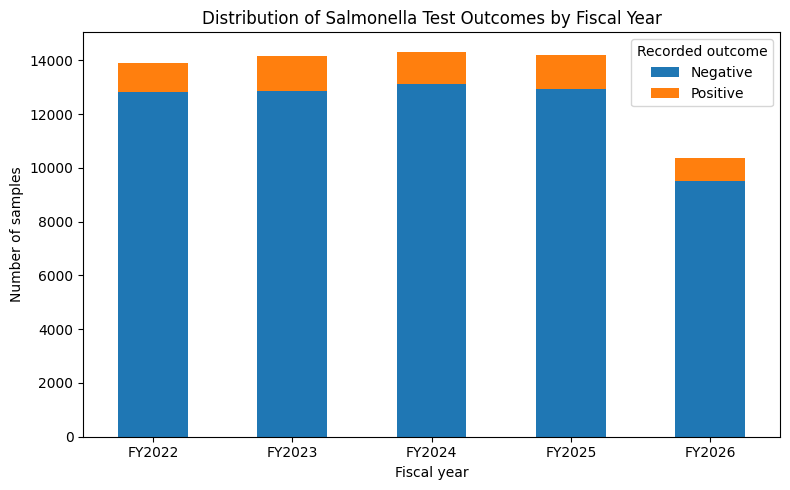

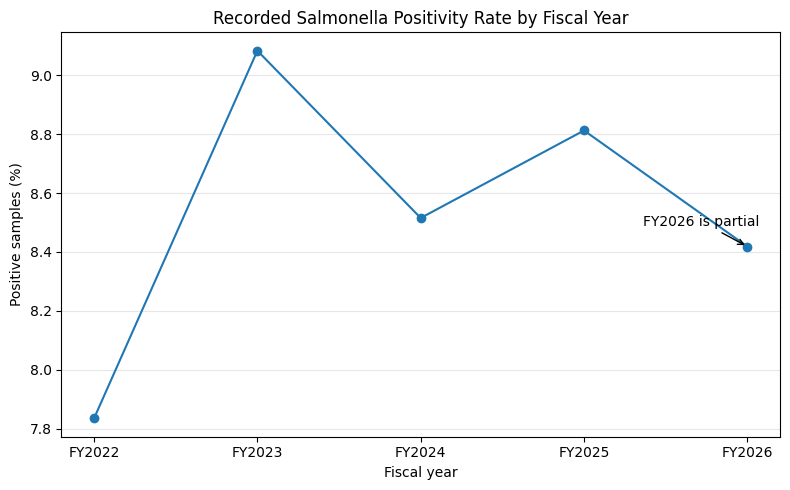

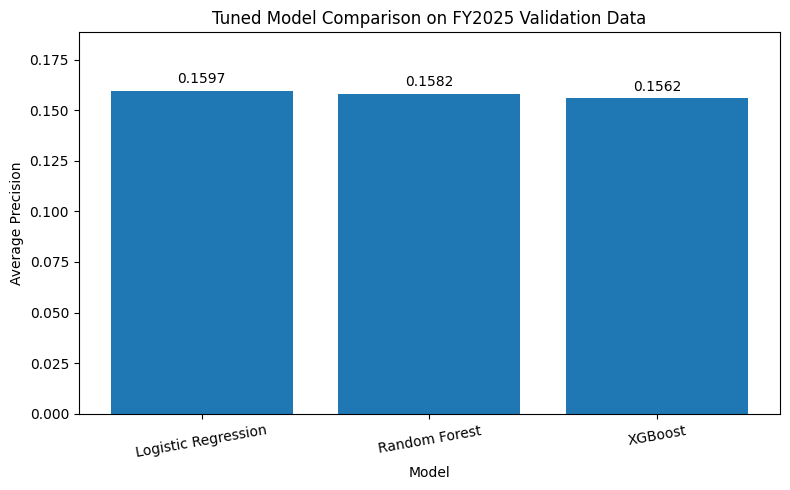

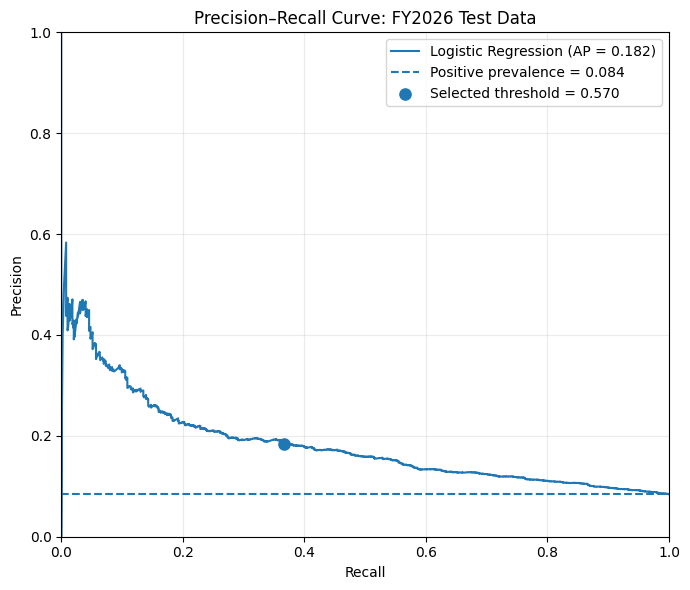

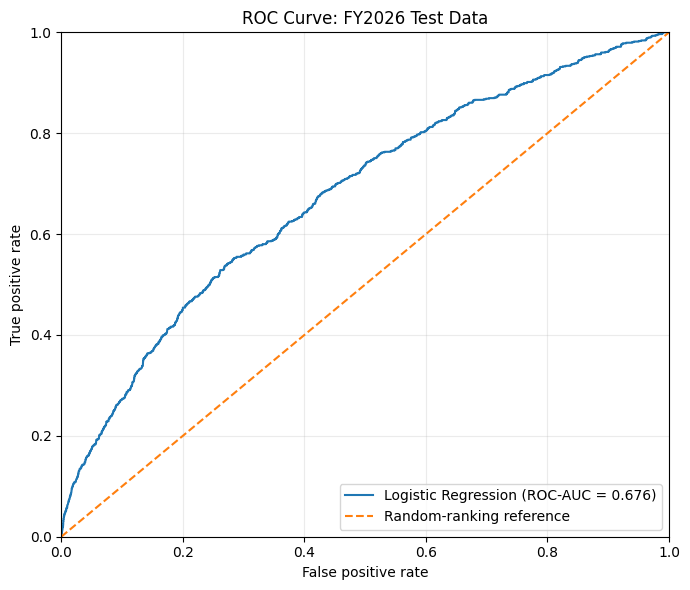

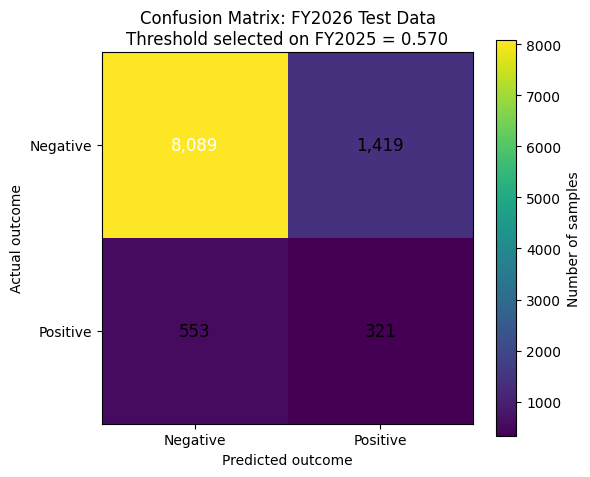


All six figures generated and saved to:
/content/drive/MyDrive/raw_poultry_ml/reports/figures
  figure1_annual_sample_distribution.png (104.4 KB)
  figure2_annual_positivity_rate.png (147.7 KB)
  figure3_validation_model_comparison_ap.png (136.2 KB)
  figure4_test_precision_recall_curve.png (139.3 KB)
  figure5_test_roc_curve.png (164.9 KB)
  figure6_test_confusion_matrix.png (126.7 KB)


In [8]:

# STEP 5: Generate final project figures
# Requires the saved final evaluation and tuning results.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    precision_score,
    recall_score,
)

# --------------------------------------------------
# 1. Paths and input files
# --------------------------------------------------

PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")

DATA_PATH = (
    PROJECT_DIR / "data" / "processed"
    / "salmonella_chicken_parts_history_v1.parquet"
)

RESULTS_DIR = PROJECT_DIR / "reports" / "results"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = (
    RESULTS_DIR / "final_tuned_logistic_predictions.csv"
)
METRICS_PATH = (
    RESULTS_DIR / "final_tuned_logistic_metrics.csv"
)
TUNING_PATH = (
    RESULTS_DIR / "hyperparameter_tuning_best_models.csv"
)

required_files = [
    DATA_PATH,
    PREDICTIONS_PATH,
    METRICS_PATH,
    TUNING_PATH,
]

missing_files = [str(p) for p in required_files if not p.exists()]

if missing_files:
    raise FileNotFoundError(
        "Run the final evaluation and tuning cells first. "
        "Missing files:\n" + "\n".join(missing_files)
    )

df = pd.read_parquet(DATA_PATH)
pred_df = pd.read_csv(PREDICTIONS_PATH)
final_metrics = pd.read_csv(METRICS_PATH)
tuning_df = pd.read_csv(TUNING_PATH)

# Verify required columns.
assert {"fiscal_year", "target_salmonella"}.issubset(df.columns)
assert {
    "target_salmonella",
    "predicted_probability",
    "predicted_class",
}.issubset(pred_df.columns)

y_true = pred_df["target_salmonella"].astype(int).to_numpy()
y_prob = pred_df["predicted_probability"].astype(float).to_numpy()
y_pred = pred_df["predicted_class"].astype(int).to_numpy()

# Use values saved with the final evaluation.
threshold = float(
    final_metrics.iloc[0]["threshold_selected_on_FY2025"]
)

print("Preparing figures...")
print("FY2026 test samples:", len(y_true))
print("FY2026 positive prevalence:", round(y_true.mean(), 4))
print("Threshold selected on FY2025:", round(threshold, 4))


# ==================================================
# FIGURE 1: Sample counts by fiscal year and outcome
# ==================================================

annual = (
    df.groupby("fiscal_year")
    .agg(
        total_samples=("target_salmonella", "size"),
        positive_samples=("target_salmonella", "sum"),
    )
    .sort_index()
)

annual["negative_samples"] = (
    annual["total_samples"] - annual["positive_samples"]
)

plot_counts = annual[
    ["negative_samples", "positive_samples"]
].copy()

plot_counts.index = [
    f"FY{int(year)}" for year in plot_counts.index
]

fig, ax = plt.subplots(figsize=(8, 5))

plot_counts.plot(
    kind="bar",
    stacked=True,
    ax=ax,
)

ax.set_title(
    "Distribution of Salmonella Test Outcomes by Fiscal Year"
)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Number of samples")
ax.legend(
    ["Negative", "Positive"],
    title="Recorded outcome",
)
ax.tick_params(axis="x", rotation=0)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure1_annual_sample_distribution.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 2: Positivity rate over time
# ==================================================

annual["positive_rate"] = (
    annual["positive_samples"] / annual["total_samples"]
)

year_labels = [f"FY{int(y)}" for y in annual.index]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    year_labels,
    annual["positive_rate"] * 100,
    marker="o",
)

ax.set_title(
    "Recorded Salmonella Positivity Rate by Fiscal Year"
)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Positive samples (%)")
ax.grid(axis="y", alpha=0.3)

# FY2026 is a partial fiscal year in this dataset.
ax.annotate(
    "FY2026 is partial",
    xy=(len(year_labels) - 1,
        annual["positive_rate"].iloc[-1] * 100),
    xytext=(-75, 15),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure2_annual_positivity_rate.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 3: Tuned-model comparison on FY2025
# Primary metric: Average Precision
# ==================================================

tuning_plot = tuning_df.sort_values(
    "best_average_precision",
    ascending=False,
).copy()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    tuning_plot["model"],
    tuning_plot["best_average_precision"],
)

ax.bar_label(bars, fmt="%.4f", padding=3)

ax.set_title(
    "Tuned Model Comparison on FY2025 Validation Data"
)
ax.set_xlabel("Model")
ax.set_ylabel("Average Precision")
ax.set_ylim(
    0,
    tuning_plot["best_average_precision"].max() * 1.18,
)
ax.tick_params(axis="x", rotation=10)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure3_validation_model_comparison_ap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 4: Precision-recall curve on FY2026
# ==================================================

precision, recall, _ = precision_recall_curve(y_true, y_prob)
average_precision = average_precision_score(y_true, y_prob)

selected_precision = precision_score(
    y_true, y_pred, zero_division=0
)
selected_recall = recall_score(
    y_true, y_pred, zero_division=0
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    recall,
    precision,
    label=f"Logistic Regression (AP = {average_precision:.3f})",
)

ax.axhline(
    y=y_true.mean(),
    linestyle="--",
    label=f"Positive prevalence = {y_true.mean():.3f}",
)

ax.scatter(
    [selected_recall],
    [selected_precision],
    marker="o",
    s=65,
    label=f"Selected threshold = {threshold:.3f}",
)

ax.set_title("Precision–Recall Curve: FY2026 Test Data")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="best")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure4_test_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 5: ROC curve on FY2026
# ==================================================

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = roc_auc_score(y_true, y_prob)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (ROC-AUC = {roc_auc:.3f})",
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random-ranking reference",
)

ax.set_title("ROC Curve: FY2026 Test Data")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure5_test_roc_curve.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ==================================================
# FIGURE 6: Confusion matrix on FY2026
# ==================================================

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(cm)
fig.colorbar(image, ax=ax, label="Number of samples")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"])
ax.set_yticklabels(["Negative", "Positive"])

ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Actual outcome")
ax.set_title(
    f"Confusion Matrix: FY2026 Test Data\n"
    f"Threshold selected on FY2025 = {threshold:.3f}"
)

midpoint = cm.max() / 2

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > midpoint else "black",
            fontsize=12,
        )

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "figure6_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# --------------------------------------------------
# Completion summary
# --------------------------------------------------

print("\nAll six figures generated and saved to:")
print(FIGURES_DIR)

for path in sorted(FIGURES_DIR.glob("figure*.png")):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")


In [22]:

# STEP 6: Inspect random individual predictions from FY2026

import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/raw_poultry_ml")
DATA_PATH = (
    PROJECT_DIR / "data" / "processed"
    / "salmonella_chicken_parts_history_v1.parquet"
)
RESULTS_DIR = PROJECT_DIR / "reports" / "results"

PREDICTIONS_PATH = (
    RESULTS_DIR / "final_tuned_logistic_predictions.csv"
)
METRICS_PATH = (
    RESULTS_DIR / "final_tuned_logistic_metrics.csv"
)

# Load previously saved data and predictions.
df_history = pd.read_parquet(DATA_PATH)
predictions = pd.read_csv(PREDICTIONS_PATH)
final_metrics = pd.read_csv(METRICS_PATH)

# Recover the FY2026 records in their original row order.
test_rows = (
    df_history[df_history["fiscal_year"] == 2026]
    .copy()
    .reset_index(drop=True)
)

# Confirm that predictions align with the correct records.
if len(test_rows) != len(predictions):
    raise ValueError(
        "Prediction and test dataset row counts do not match."
    )

if not np.array_equal(
    test_rows["target_salmonella"].astype(int).to_numpy(),
    predictions["target_salmonella"].astype(int).to_numpy(),
):
    raise ValueError(
        "Actual labels do not align with saved predictions. "
        "Do not inspect until row alignment is resolved."
    )

if not np.array_equal(
    test_rows["establishment_id"].astype(str).to_numpy(),
    predictions["establishment_id"].astype(str).to_numpy(),
):
    raise ValueError(
        "Establishment IDs do not align with saved predictions."
    )

# Combine predictors and saved model outputs.
inspect_df = test_rows[
    [
        "establishment_id",
        "fiscal_year",
        "establishment_state",
        "product_type",
        "collection_month",
        "project_code",
        "prior_sample_count",
        "prior_positive_rate",
        "target_salmonella",
    ]
].copy()

inspect_df = inspect_df.rename(
    columns={"target_salmonella": "actual"}
)

inspect_df["predicted_probability"] = (
    predictions["predicted_probability"].to_numpy()
)
inspect_df["predicted"] = (
    predictions["predicted_class"].astype(int).to_numpy()
)

threshold = float(
    final_metrics.iloc[0]["threshold_selected_on_FY2025"]
)

inspect_df["threshold"] = threshold

# Translate numeric labels into readable outcomes.
label_map = {0: "Negative", 1: "Positive"}

inspect_df["actual_outcome"] = inspect_df["actual"].map(label_map)
inspect_df["predicted_outcome"] = inspect_df["predicted"].map(label_map)

inspect_df["correct"] = (
    inspect_df["actual"] == inspect_df["predicted"]
)

def prediction_type(row):
    if row["actual"] == 1 and row["predicted"] == 1:
        return "True Positive"
    elif row["actual"] == 0 and row["predicted"] == 0:
        return "True Negative"
    elif row["actual"] == 0 and row["predicted"] == 1:
        return "False Positive"
    else:
        return "False Negative"

inspect_df["prediction_type"] = inspect_df.apply(
    prediction_type, axis=1
)

# Randomly select 20 records, reproducibly.
random_sample = inspect_df.sample(
    n=min(20, len(inspect_df)),
    #random_state=42,
).reset_index(drop=True)

display_columns = [
    "establishment_id",
    "establishment_state",
    "product_type",
    "collection_month",
    "actual_outcome",
    "predicted_outcome",
    "predicted_probability",
    "prediction_type",
    "correct",
]

print(f"Threshold selected using FY2025: {threshold:.4f}")
print("20 randomly selected FY2026 predictions:")
display(random_sample[display_columns].round(4))

# Summarize all test predictions, not just the random sample.
print("\nPrediction outcomes across the complete FY2026 test set:")
summary = (
    inspect_df["prediction_type"]
    .value_counts()
    .reindex(
        [
            "True Positive",
            "True Negative",
            "False Positive",
            "False Negative",
        ],
        fill_value=0,
    )
    .rename_axis("prediction_type")
    .reset_index(name="sample_count")
)

summary["percentage_of_test_set"] = (
    100 * summary["sample_count"] / len(inspect_df)
)

display(summary.round(2))




Threshold selected using FY2025: 0.5700
20 randomly selected FY2026 predictions:


,establishment_id,establishment_state,product_type,collection_month,actual_outcome,predicted_outcome,predicted_probability,prediction_type,correct
0,2793,IL,Breast,6,Negative,Positive,0.7124,False Positive,False
1,4507,MS,Breast,4,Negative,Negative,0.3334,True Negative,True
2,2260,DE,Wing,11,Negative,Negative,0.4479,True Negative,True
3,63,GA,Wing,2,Negative,Negative,0.3791,True Negative,True
4,4340,TX,Breast,10,Negative,Positive,0.6279,False Positive,False
5,6166551,NY,Leg,1,Negative,Negative,0.3812,True Negative,True
6,4513,MS,Leg,5,Negative,Negative,0.2749,True Negative,True
7,13936,MD,Breast,1,Negative,Positive,0.6587,False Positive,False
8,6163678,AL,Leg,3,Negative,Negative,0.3747,True Negative,True
9,638,SC,Leg,10,Negative,Negative,0.4122,True Negative,True



Prediction outcomes across the complete FY2026 test set:


,prediction_type,sample_count,percentage_of_test_set
0,True Positive,321,3.09
1,True Negative,8089,77.91
2,False Positive,1419,13.67
3,False Negative,553,5.33
